# Wet Waste (Organic Waste), Nonthaburi Province

**Data:** `data/raw/wet.csv` — organic waste separated into bins (tonnes), e.g. food scraps, vegetable scraps, leaves, per local government per month, Buddhist Era 2563–2567 (2020–2024)

Organic waste is **the largest part (~40%)** of Nonthaburi's waste (see the waste-types notebook). Separating more of it reduces the landfill burden and can be turned into compost/biogas

**Steps:** load → convert numbers → fix outliers → save `clean_wet.csv` → charts: trend, by district, seasonality, top local governments, the effect of cleaning, separation rate relative to all waste, and a **comparison with recyclable waste**

# ปริมาณขยะเปียก (ขยะอินทรีย์) จังหวัดนนทบุรี

**ข้อมูล:** `data/raw/wet.csv` — ปริมาณขยะอินทรีย์ที่คัดแยกลงถัง (ตัน) เช่น เศษอาหาร เศษผัก ใบไม้ ราย อปท. รายเดือน พ.ศ. 2563–2567

ขยะอินทรีย์คือ **ส่วนที่ใหญ่ที่สุด (~40%)** ของขยะนนทบุรี (ดู notebook ประเภทขยะมูลฝอย) ถ้าแยกได้มากจะลดภาระฝังกลบและนำไปทำปุ๋ยหมัก/ก๊าซชีวภาพได้

**ขั้นตอน:** โหลด → แปลงตัวเลข → แก้ค่าผิดปกติ → บันทึก `clean_wet.csv` → กราฟ: แนวโน้ม, รายอำเภอ, ฤดูกาล, อปท. อันดับต้น, ผลของการทำความสะอาด, อัตราคัดแยกเทียบขยะทั้งหมด และ **เทียบกับขยะรีไซเคิล**

**Import libraries** — `pandas` handles tabular data (DataFrame) and `numpy` handles numbers/missing values (`np.nan`)

**นำเข้าไลบรารี** — `pandas` ใช้จัดการข้อมูลแบบตาราง (DataFrame) และ `numpy` ใช้คำนวณตัวเลข/จัดการค่าว่าง (`np.nan`)

In [1]:
import pandas as pd
import numpy as np

**Load the raw data** from `../data/raw/wet.csv`

**โหลดข้อมูลดิบ** จาก `../data/raw/wet.csv`

In [2]:
df = pd.read_csv('../data/raw/wet.csv')
df

,ปี,เดือน,จังหวัด,อำเภอ,อปท,ขยะอินทรีย์ลงถัง(ตัน)
0,2563,มกราคม,นนทบุรี,ไทรน้อย,เทศบาลตำบลไทรน้อย,49.17
1,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ทวีวัฒนา,63
2,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.หนองเพรางาย,120
3,2563,มกราคม,นนทบุรี,บางกรวย,เทศบาลเมืองบางกรวย,400
4,2563,มกราคม,นนทบุรี,บางกรวย,เทศบาลตำบลบางสีทอง,261
...,...,...,...,...,...,...
2014,2567,ธันวาคม,นนทบุรี,เมืองนนทบุรี,เทศบาลเมืองไทรม้า,0
2015,2567,ธันวาคม,นนทบุรี,เมืองนนทบุรี,เทศบาลเมืองบางกร่าง,85.95
2016,2567,ธันวาคม,นนทบุรี,เมืองนนทบุรี,เทศบาลเมืองบางศรีเมือง,668.279
2017,2567,ธันวาคม,นนทบุรี,เมืองนนทบุรี,อบต.บางไผ่,441.42


**Check the data structure** with `df.info()` — number of rows, data types (dtype) and number of non-empty values in each column

Common issue: numeric columns with comma separators (e.g. `"1,234"`) are read as `object` (text) and must be converted to numbers before calculating

**ตรวจสอบโครงสร้างข้อมูล** ด้วย `df.info()` — ดูจำนวนแถว ชนิดข้อมูล (dtype) และจำนวนค่าที่ไม่ว่างของแต่ละคอลัมน์

สิ่งที่มักพบ: คอลัมน์ตัวเลขที่มีเครื่องหมายจุลภาค (เช่น `"1,234"`) จะถูกอ่านเป็น `object` (ข้อความ) ต้องแปลงเป็นตัวเลขก่อนนำไปคำนวณ

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2019 entries, 0 to 2018
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   ปี                     2019 non-null   int64 
 1   เดือน                  2019 non-null   object
 2   จังหวัด                2019 non-null   object
 3   อำเภอ                  2019 non-null   object
 4   อปท                    2019 non-null   object
 5   ขยะอินทรีย์ลงถัง(ตัน)  2019 non-null   object
dtypes: int64(1), object(5)
memory usage: 94.8+ KB


**Data type conversion**
- Text columns with repeated values (month, province, district, local government) are converted to `category` to save memory and make `groupby` faster
- Numeric columns stored as text: remove `,` with `str.replace`, then convert to `float`
- **Fix swapped columns (2566–2567):** in the raw file 1,038 rows have the `เดือน` (month) and `จังหวัด` (province) values swapped (the month column says "นนทบุรี"), so they are swapped back before converting to `category` — without this fix the monthly charts would have no data for the last 2 years

**แปลงชนิดข้อมูล (Data type conversion)**
- คอลัมน์ข้อความที่มีค่าซ้ำ ๆ (เดือน, จังหวัด, อำเภอ, อปท) แปลงเป็น `category` เพื่อประหยัดหน่วยความจำและทำ `groupby` ได้เร็วขึ้น
- คอลัมน์ตัวเลขที่เก็บเป็นข้อความ: ลบเครื่องหมาย `,` ด้วย `str.replace` แล้วแปลงเป็น `float`

In [4]:
for col in df.columns[1:5]:
    df[col] = df[col].astype('category')
df['ขยะอินทรีย์ลงถัง(ตัน)'] = df['ขยะอินทรีย์ลงถัง(ตัน)'].str.replace(',', '', regex=False).astype(float)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2019 entries, 0 to 2018
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   ปี                     2019 non-null   int64   
 1   เดือน                  2019 non-null   category
 2   จังหวัด                2019 non-null   category
 3   อำเภอ                  2019 non-null   category
 4   อปท                    2019 non-null   category
 5   ขยะอินทรีย์ลงถัง(ตัน)  2019 non-null   float64 
dtypes: category(4), float64(1), int64(1)
memory usage: 41.7 KB


**Back up the data before fixing outliers** — keep a copy in `df_before_clean` to compare before/after cleaning in the chart section

**สำรองข้อมูลก่อนแก้ค่าผิดปกติ** — เก็บสำเนาไว้ใน `df_before_clean` เพื่อนำไปเปรียบเทียบผลก่อน/หลังทำความสะอาดในส่วนกราฟ

In [5]:
df_before_clean = df.copy()   # kept to compare before/after fixing outliers — สำรองไว้เทียบผลก่อน/หลังแก้ค่าผิดปกติ

**Outlier treatment** for the column `ขยะอินทรีย์ลงถัง(ตัน)`

1. Find the **median of each local government** with `groupby('อปท').transform('median')` — each one's own median is used because local governments differ greatly in size (city municipality vs subdistrict administrative organization)
2. If a month's value is **more than 10 times its own median and more than 500 tonnes**, it is treated as an outlier (usually a number typed with the wrong number of digits)
3. Replace that outlier with the local government's median

The "more than 500 tonnes" condition prevents small local governments whose normal values are near 0 from being changed unnecessarily

Finally, the helper columns (`median_...`) are removed with `df = df.drop(columns=[...])` so they don't end up in the clean file

> Fixed: this used to be `df.drop(columns=[...])` without assigning back to `df`, so the clean file kept the helper columns

**แก้ค่าผิดปกติ (Outlier treatment)** ของคอลัมน์ `ขยะอินทรีย์ลงถัง(ตัน)`

1. หา **ค่ามัธยฐาน (median) ของแต่ละ อปท.** ด้วย `groupby('อปท').transform('median')` — ใช้ median ของตัวเองเพราะ อปท. แต่ละแห่งมีขนาดต่างกันมาก (เทศบาลนคร vs อบต.)
2. ถ้าค่าในเดือนใด **สูงกว่า 10 เท่าของ median ตัวเอง และมากกว่า 500 ตัน** ถือว่าผิดปกติ (มักเกิดจากการกรอกตัวเลขผิดหลัก)
3. แทนค่าผิดปกตินั้นด้วย median ของ อปท. นั้น

เงื่อนไข "มากกว่า 500 ตัน" ช่วยป้องกันไม่ให้ อปท. เล็ก ๆ ที่ค่าปกติใกล้ 0 ถูกแก้ค่าโดยไม่จำเป็น

สุดท้ายลบคอลัมน์ช่วยคำนวณ (`median_...`) ออกด้วย `df = df.drop(columns=[...])` เพื่อไม่ให้ติดไปในไฟล์ clean

> แก้ไขแล้ว: เดิมเขียนเป็น `df.drop(columns=[...])` โดยไม่ได้ assign กลับเข้า `df` ทำให้ไฟล์ clean มีคอลัมน์ช่วยคำนวณติดไปด้วย

In [6]:
# Find the median
# หาค่ากลาง
df['median_val'] = df.groupby('อปท')['ขยะอินทรีย์ลงถัง(ตัน)'].transform('median')

# Condition: if more than 10 times the median and more than 500 tonnes, fix it
# เงื่อนไข: ถ้าเกิน 10 เท่าของค่ากลาง และมากกว่า 500 ตัน ให้แก้
condition = (df['ขยะอินทรีย์ลงถัง(ตัน)'] > df['median_val'] * 10) & (df['ขยะอินทรีย์ลงถัง(ตัน)'] > 500)
df.loc[condition, 'ขยะอินทรีย์ลงถัง(ตัน)'] = df.loc[condition, 'median_val']

# Drop the helper median columns (only needed for the calculation above)
# ลบคอลัมน์ช่วยคำนวณ median ทิ้ง (ใช้แค่ในการคำนวณด้านบน)
df = df.drop(columns=['median_val'])
df.head()

/var/folders/jp/qywn4qv17q56wh6qhsrjcmk80000gn/T/ipykernel_47272/3929328216.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df['median_val'] = df.groupby('อปท')['ขยะอินทรีย์ลงถัง(ตัน)'].transform('median')


,ปี,เดือน,จังหวัด,อำเภอ,อปท,ขยะอินทรีย์ลงถัง(ตัน)
0,2563,มกราคม,นนทบุรี,ไทรน้อย,เทศบาลตำบลไทรน้อย,49.17
1,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ทวีวัฒนา,63.00
2,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.หนองเพรางาย,120.00
3,2563,มกราคม,นนทบุรี,บางกรวย,เทศบาลเมืองบางกรวย,400.00
4,2563,มกราคม,นนทบุรี,บางกรวย,เทศบาลตำบลบางสีทอง,261.00


**Save the cleaned data** to the `data/clean/` folder so other notebooks and the web app can use it

> Note: without `index=False` the CSV file gets a row-index column (it shows up as `Unnamed: 0` when read back)

**บันทึกข้อมูลที่ทำความสะอาดแล้ว** ลงโฟลเดอร์ `data/clean/` เพื่อให้ notebook อื่นและเว็บแอปนำไปใช้ต่อ

> หมายเหตุ: ถ้าไม่ใส่ `index=False` ไฟล์ CSV จะมีคอลัมน์ลำดับแถว (เปิดอ่านแล้วจะเห็นเป็น `Unnamed: 0`)

In [7]:
df.to_csv('../data/clean/clean_wet.csv')

---
# Part 2: Data Visualization

This part turns the cleaned data into several kinds of charts to answer **"what is happening in this data"** across time (yearly/monthly), area (district/local government) and proportions

**The next cell sets up shared chart settings used by every chart:**
- Picks a **Thai font** available on the machine (Tahoma / Thonburi / Leelawadee UI, etc.) so Thai text does not turn into boxes
- Defines a **color palette (PALETTE)** tested for color-vision deficiency, and a fixed **color per district (DIST_COLOR)** — the same district has the same color in every chart and every notebook
- Creates **helper functions** `bar_labels` (numbers on bars), `stacked_bar` (stacked bar chart), `pie_chart` (pie chart)
- Creates a `viz` table, a copy of the data with category columns converted back to text so `groupby` is simple and produces no empty groups

# ส่วนที่ 2: การแสดงผลข้อมูล (Data Visualization)

ส่วนนี้นำข้อมูลที่ทำความสะอาดแล้วมาสร้างกราฟหลายรูปแบบ เพื่อตอบคำถามว่า **"เกิดอะไรขึ้นกับข้อมูลนี้"** ทั้งในมิติ เวลา (รายปี/รายเดือน) พื้นที่ (รายอำเภอ/อปท.) และสัดส่วน

**เซลล์ถัดไปเป็นการตั้งค่ากราฟที่ใช้ร่วมกันทุกกราฟ:**
- เลือก **ฟอนต์ภาษาไทย** ที่มีในเครื่อง (Tahoma / Thonburi / Leelawadee UI ฯลฯ) เพื่อไม่ให้ตัวอักษรไทยกลายเป็นสี่เหลี่ยม
- กำหนด **ชุดสี (PALETTE)** ที่ผ่านการทดสอบสำหรับผู้มีภาวะตาบอดสี และกำหนด **สีประจำอำเภอ (DIST_COLOR)** ให้คงที่ — อำเภอเดียวกันจะเป็นสีเดียวกันในทุกกราฟและทุก notebook
- สร้าง **ฟังก์ชันช่วย** `bar_labels` (ใส่ตัวเลขบนแท่ง), `stacked_bar` (กราฟแท่งซ้อน), `pie_chart` (แผนภูมิวงกลม)
- สร้างตาราง `viz` ซึ่งเป็นสำเนาของข้อมูลที่แปลงคอลัมน์ category กลับเป็นข้อความ เพื่อให้ `groupby` ทำงานง่ายและไม่เกิดกลุ่มว่าง

In [8]:
# ── Chart setup (shared by every chart in this section) ─────────────────
# ── ตั้งค่ากราฟ (ใช้ร่วมกันทุกกราฟในส่วนนี้) ─────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm, to_rgb
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# 1) Thai font: pick the first one available on this machine
# 1) ฟอนต์ภาษาไทย: เลือกตัวแรกที่มีในเครื่อง
thai_fonts = ['Tahoma', 'Thonburi', 'Leelawadee UI', 'TH Sarabun New', 'Noto Sans Thai']
available = {f.name for f in fm.fontManager.ttflist}
thai_font = next((f for f in thai_fonts if f in available), 'DejaVu Sans')
plt.rcParams.update({
    'font.family': thai_font, 'axes.unicode_minus': False,
    'figure.dpi': 110, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#bdbcb6', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.grid': True, 'grid.color': '#e8e7e2', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.titlesize': 14, 'axes.titleweight': 'bold', 'axes.titlepad': 12,
    'legend.frameon': False,
})
print(f'ใช้ฟอนต์: {thai_font}')

# 2) Color palette (fixed order — checked for color-vision-deficiency separation)
# 2) ชุดสี (เรียงลำดับคงที่ — ผ่านการตรวจความแตกต่างสำหรับผู้มีภาวะตาบอดสี)
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
GRAY = '#9a9992'
TEXT = '#52514e'
DIST_ORDER = ['เมืองนนทบุรี', 'บางกรวย', 'บางใหญ่', 'บางบัวทอง', 'ไทรน้อย', 'ปากเกร็ด']
DIST_COLOR = dict(zip(DIST_ORDER, PALETTE))           # color per district (fixed across all charts) — สีประจำอำเภอ (คงที่ทุกกราฟ)
MONTHS = ['มกราคม', 'กุมภาพันธ์', 'มีนาคม', 'เมษายน', 'พฤษภาคม', 'มิถุนายน',
          'กรกฎาคม', 'สิงหาคม', 'กันยายน', 'ตุลาคม', 'พฤศจิกายน', 'ธันวาคม']
MONTHS_SHORT = ['ม.ค.', 'ก.พ.', 'มี.ค.', 'เม.ย.', 'พ.ค.', 'มิ.ย.',
                'ก.ค.', 'ส.ค.', 'ก.ย.', 'ต.ค.', 'พ.ย.', 'ธ.ค.']
SEQ_CMAP = LinearSegmentedColormap.from_list('seq_blue', ['#eef4fc', '#86b6ef', '#2a78d6', '#104281'])
DIV_CMAP = LinearSegmentedColormap.from_list('div_blue_orange', ['#2a78d6', '#f0efec', '#eb6834'])
fmt_k = mtick.FuncFormatter(lambda x, _: f'{x:,.0f}')


def bar_labels(ax, bars, fmt='{:,.0f}', horizontal=False, fontsize=9):
    """Write the value at the end of each bar — เขียนตัวเลขกำกับที่ปลายแท่ง"""
    for b in bars:
        v = b.get_width() if horizontal else b.get_height()
        if horizontal:
            ax.text(v, b.get_y() + b.get_height() / 2, '  ' + fmt.format(v),
                    va='center', ha='left', fontsize=fontsize, color=TEXT)
        else:
            ax.text(b.get_x() + b.get_width() / 2, v, fmt.format(v),
                    ha='center', va='bottom', fontsize=fontsize, color=TEXT)


def stacked_bar(ax, table, colors=None, horizontal=False):
    """Stacked bar chart: table index = main axis, columns = stacked groups; returns each bar's total — กราฟแท่งซ้อน: index ของ table = แกนหลัก, columns = กลุ่มที่ซ้อนกัน; คืนค่ายอดรวมของแต่ละแท่ง"""
    if colors is None:
        colors = [DIST_COLOR.get(c, PALETTE[i % len(PALETTE)]) for i, c in enumerate(table.columns)]
    pos = np.arange(len(table))
    base = np.zeros(len(table))
    for c, color in zip(table.columns, colors):
        vals = table[c].fillna(0).to_numpy(dtype=float)
        if horizontal:
            ax.barh(pos, vals, left=base, color=color, edgecolor='white', linewidth=1, height=0.65, label=str(c))
        else:
            ax.bar(pos, vals, bottom=base, color=color, edgecolor='white', linewidth=1, width=0.65, label=str(c))
        base += vals
    if horizontal:
        ax.set_yticks(pos, [str(i) for i in table.index]); ax.grid(axis='y', visible=False)
    else:
        ax.set_xticks(pos, [str(i) for i in table.index]); ax.grid(axis='x', visible=False)
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
    return base


def end_labels(ax, x, items, min_gap_frac=0.045):
    """Labels at the end of lines (items = [(name, y value)]) — spaced apart automatically so they do not overlap — ชื่อกำกับที่ปลายเส้น (items = [(ชื่อ, ค่า y)]) — ขยับห่างกันอัตโนมัติไม่ให้ทับกัน"""
    lo, hi = ax.get_ylim()
    gap = (hi - lo) * min_gap_frac
    items = sorted(items, key=lambda t: t[1])
    ys = [y for _, y in items]
    for i in range(1, len(ys)):
        ys[i] = max(ys[i], ys[i - 1] + gap)
    for (lab, _), y in zip(items, ys):
        ax.annotate(lab, (x, y), xytext=(8, 0), textcoords='offset points', va='center',
                    fontsize=9, color=TEXT, annotation_clip=False)


def ref_line(ax, value, label, axis='y'):
    """Reference line (average/target) with its label outside the plot area so it does not cover bars — เส้นอ้างอิง (ค่าเฉลี่ย/เป้าหมาย) พร้อมป้ายกำกับนอกพื้นที่กราฟ ไม่ทับแท่ง"""
    if axis == 'y':
        ax.axhline(value, color=TEXT, linewidth=1, linestyle='--')
        ax.text(1.01, value, label, transform=ax.get_yaxis_transform(), va='center', ha='left', fontsize=9, color=TEXT)
    else:
        ax.axvline(value, color=TEXT, linewidth=1, linestyle='--')
        ax.text(value, 1.01, label, transform=ax.get_xaxis_transform(), va='bottom', ha='center', fontsize=9, color=TEXT)


def _ink(color):
    r, g, b = to_rgb(color)
    return '#0b0b0b' if (0.299 * r + 0.587 * g + 0.114 * b) > 0.6 else 'white'


def pie_chart(ax, values, labels, colors=None, title='', min_pct=4):
    """Pie chart: % inside slices that are big enough, name + % of every slice in the legend — แผนภูมิวงกลม: % ในชิ้นที่ใหญ่พอ, ชื่อ + % ทุกชิ้นอยู่ใน legend"""
    values = np.asarray(values, dtype=float)
    labels = [str(l) for l in labels]
    colors = colors or PALETTE[:len(values)]
    total = values.sum()
    wedges, _, autotexts = ax.pie(
        values, colors=colors, startangle=90, counterclock=False, pctdistance=0.7,
        autopct=lambda p: f'{p:.1f}%' if p >= min_pct else '',
        wedgeprops=dict(edgecolor='white', linewidth=2))
    for w, t in zip(wedges, autotexts):
        t.set_color(_ink(w.get_facecolor())); t.set_fontsize(10); t.set_fontweight('bold')
    ax.legend(wedges, [f'{l}  {v:,.0f} ({v / total * 100:.1f}%)' for l, v in zip(labels, values)],
              loc='center left', bbox_to_anchor=(1, 0.5), fontsize=10)
    ax.set_title(title)
    ax.axis('equal')

ใช้ฟอนต์: Tahoma


In [9]:
# Copy of the data for charting: convert category → text (does not affect the original table)
# สำเนาข้อมูลสำหรับทำกราฟ: แปลง category → ข้อความ (ไม่กระทบตารางต้นฉบับ)
viz = df.copy()
for c in viz.select_dtypes('category').columns:
    viz[c] = viz[c].astype(str)
viz = viz.loc[:, ~viz.columns.str.startswith(('median', 'Unnamed'))]   # drop helper columns — ตัดคอลัมน์ช่วยคำนวณ
print(viz.shape)
viz.head()

(2019, 6)


,ปี,เดือน,จังหวัด,อำเภอ,อปท,ขยะอินทรีย์ลงถัง(ตัน)
0,2563,มกราคม,นนทบุรี,ไทรน้อย,เทศบาลตำบลไทรน้อย,49.17
1,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ทวีวัฒนา,63.00
2,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.หนองเพรางาย,120.00
3,2563,มกราคม,นนทบุรี,บางกรวย,เทศบาลเมืองบางกรวย,400.00
4,2563,มกราคม,นนทบุรี,บางกรวย,เทศบาลตำบลบางสีทอง,261.00


### 2.1 Line chart: total organic waste per year
**What it does:** sums every local government (อปท.) and every month within each year (`groupby('ปี').sum()`) and draws it as a line

**How to read it:** a rising line = more than the previous year, a falling line = less. The number on each point is that year's total (tonnes)

> Caution: if the number of reporting local governments differs between years, the total can change because of "reporting", not because of the real amount

### 2.1 กราฟเส้น: ปริมาณขยะอินทรีย์รวมรายปี
**ทำอะไร:** รวมค่าของทุก อปท. ทุกเดือนในแต่ละปี (`groupby('ปี').sum()`) แล้ววาดเป็นเส้น

**วิธีอ่าน:** เส้นที่ชันขึ้น = ปริมาณเพิ่มขึ้นจากปีก่อน, เส้นลง = ลดลง ตัวเลขบนจุดคือยอดรวมของปีนั้น (ตัน)

> ข้อควรระวัง: หากบางปีมีจำนวน อปท. ที่รายงานข้อมูลไม่เท่ากัน ยอดรวมอาจเปลี่ยนเพราะ "การรายงาน" ไม่ใช่เพราะปริมาณจริง

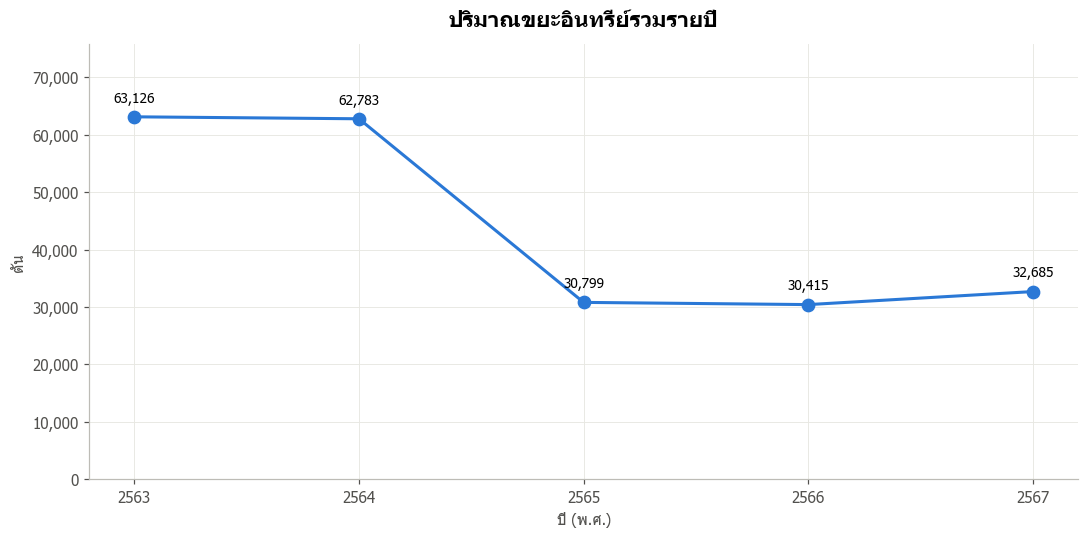

เปลี่ยนแปลงจากปีก่อน (%):
ปี
2564    -0.5
2565   -50.9
2566    -1.2
2567     7.5


In [10]:
col = 'ขยะอินทรีย์ลงถัง(ตัน)'
yearly = viz.groupby('ปี')[col].sum()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(yearly.index, yearly.values, marker='o', markersize=8, linewidth=2, color=PALETTE[0])
for x, y in zip(yearly.index, yearly.values):
    ax.annotate(f'{y:,.0f}', (x, y), textcoords='offset points', xytext=(0, 10), ha='center', fontsize=9)
ax.set_xticks(yearly.index)
ax.set_ylim(0, yearly.max() * 1.2)
ax.yaxis.set_major_formatter(fmt_k)
ax.set_title('ปริมาณขยะอินทรีย์รวมรายปี')
ax.set_xlabel('ปี (พ.ศ.)'); ax.set_ylabel('ตัน')
plt.tight_layout(); plt.show()

print('เปลี่ยนแปลงจากปีก่อน (%):')
print(yearly.pct_change().mul(100).round(1).dropna().to_string())

### 2.2 Stacked bar chart: yearly totals by district
**What it does:** builds a pivot table (rows = year, columns = district) and draws the bars stacked on top of each other

**How to read it:** the full bar height = that year's total, and each color is one district's share — it shows "which district the rise/fall in the total comes from"

### 2.2 กราฟแท่งซ้อน (Stacked Bar): ยอดรายปีแยกตามอำเภอ
**ทำอะไร:** สร้างตาราง pivot (แถว = ปี, คอลัมน์ = อำเภอ) แล้ววาดแท่งซ้อนกัน

**วิธีอ่าน:** ความสูงทั้งแท่ง = ยอดรวมของปีนั้น, แต่ละสีคือส่วนของแต่ละอำเภอ ช่วยให้เห็นว่า "การเพิ่ม/ลดของยอดรวม มาจากอำเภอไหน"

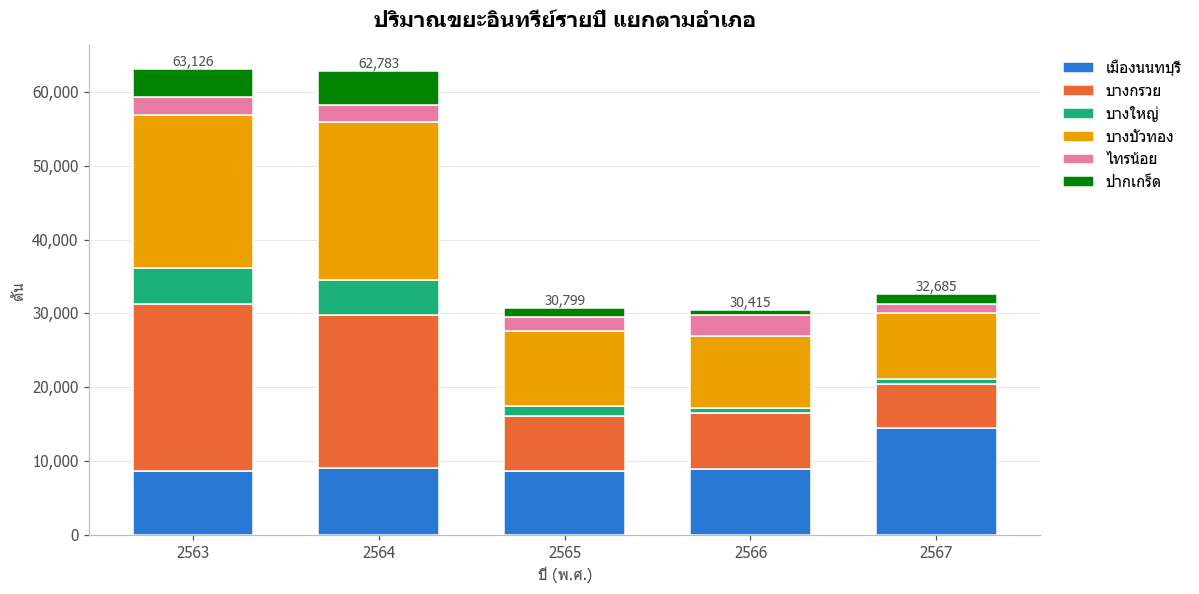

อำเภอ,เมืองนนทบุรี,บางกรวย,บางใหญ่,บางบัวทอง,ไทรน้อย,ปากเกร็ด
ปี,,,,,,
2563,8676.4,22667.1,4784.0,20684.0,2452.5,3862.4
2564,9098.9,20732.6,4703.3,21309.7,2310.0,4628.3
2565,8706.5,7426.5,1288.8,10219.1,1861.8,1296.7
2566,8925.7,7656.2,672.1,9689.4,2786.6,685.4
2567,14551.5,5884.5,687.8,8964.9,1194.1,1401.9


In [11]:
col = 'ขยะอินทรีย์ลงถัง(ตัน)'
pivot = (viz.pivot_table(index='ปี', columns='อำเภอ', values=col, aggfunc='sum')
            .reindex(columns=[d for d in DIST_ORDER if d in set(viz['อำเภอ'])]))

fig, ax = plt.subplots(figsize=(11, 5.5))
totals = stacked_bar(ax, pivot)
for i, t in enumerate(totals):
    ax.text(i, t, f'{t:,.0f}', ha='center', va='bottom', fontsize=9, color=TEXT)
ax.yaxis.set_major_formatter(fmt_k)
ax.set_title('ปริมาณขยะอินทรีย์รายปี แยกตามอำเภอ')
ax.set_xlabel('ปี (พ.ศ.)'); ax.set_ylabel('ตัน')
plt.tight_layout(); plt.show()
pivot.round(1)

### 2.3 Horizontal bar + pie chart: comparison by district (all years combined)
**What it does:** sums organic waste for each district over all years
- **Horizontal bar chart**, sorted from smallest to largest → compares "size" precisely
- **Pie chart** → shows the "share": what % of the province each district accounts for (each district keeps the same color as in the other charts)

### 2.3 กราฟแท่งแนวนอน + แผนภูมิวงกลม: เปรียบเทียบรายอำเภอ (รวมทุกปี)
**ทำอะไร:** รวมปริมาณขยะอินทรีย์ของแต่ละอำเภอตลอดทุกปี
- **กราฟแท่งแนวนอน** เรียงจากน้อยไปมาก → เทียบ "ขนาด" ได้แม่นยำ
- **แผนภูมิวงกลม (Pie chart)** → ดู "สัดส่วน" ว่าแต่ละอำเภอคิดเป็นกี่ % ของทั้งจังหวัด (สีของแต่ละอำเภอเหมือนกับกราฟอื่น)

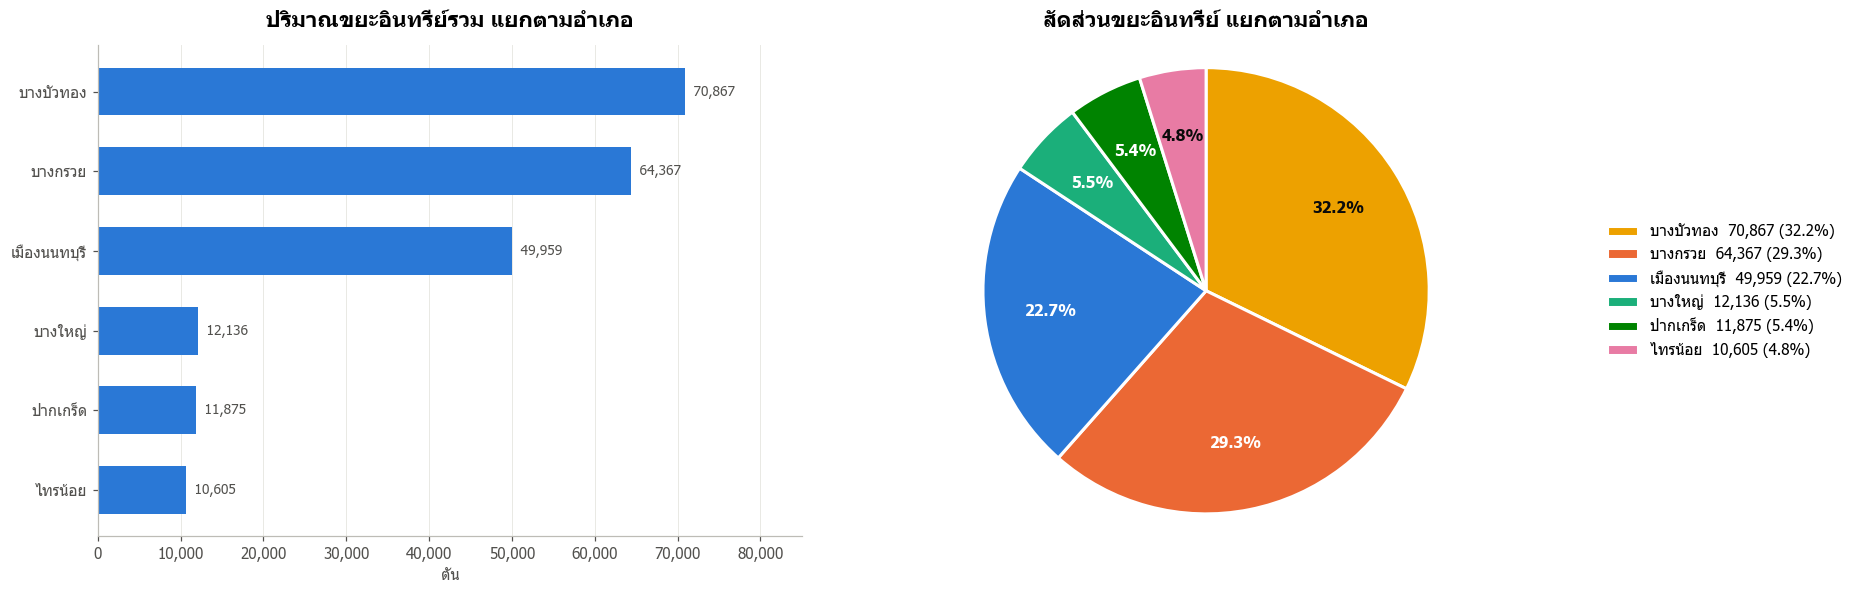

In [12]:
col = 'ขยะอินทรีย์ลงถัง(ตัน)'
by_dist = viz.groupby('อำเภอ')[col].sum().sort_values()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={'width_ratios': [1, 1.1]})
bars = ax1.barh(by_dist.index, by_dist.values, color=PALETTE[0], height=0.6)
bar_labels(ax1, bars, horizontal=True)
ax1.set_xlim(0, by_dist.max() * 1.2)
ax1.xaxis.set_major_formatter(fmt_k); ax1.grid(axis='y', visible=False)
ax1.set_title('ปริมาณขยะอินทรีย์รวม แยกตามอำเภอ'); ax1.set_xlabel('ตัน')

share = by_dist[by_dist > 0].sort_values(ascending=False)
pie_chart(ax2, share.values, share.index, colors=[DIST_COLOR.get(d, GRAY) for d in share.index],
          title='สัดส่วนขยะอินทรีย์ แยกตามอำเภอ')
plt.tight_layout(); plt.show()

### 2.4 Bar chart: seasonal pattern (average by month)
**What it does:** first totals each "year-month", then averages the same month across years (e.g. every January averaged together)

**How to read it:** bars above the dashed line (the average of all months) = months with more than usual — useful for planning staff/collection trucks by season

### 2.4 กราฟแท่ง: รูปแบบตามฤดูกาล (ค่าเฉลี่ยรายเดือน)
**ทำอะไร:** หายอดรวมของแต่ละ "ปี-เดือน" ก่อน แล้วเฉลี่ยข้ามปีของเดือนเดียวกัน (เช่น ม.ค. ทุกปีมาเฉลี่ยกัน)

**วิธีอ่าน:** แท่งที่สูงกว่าเส้นประ (ค่าเฉลี่ยทุกเดือน) = เดือนที่มีปริมาณมากกว่าปกติ ช่วยวางแผนกำลังคน/รถเก็บขนตามฤดูกาล

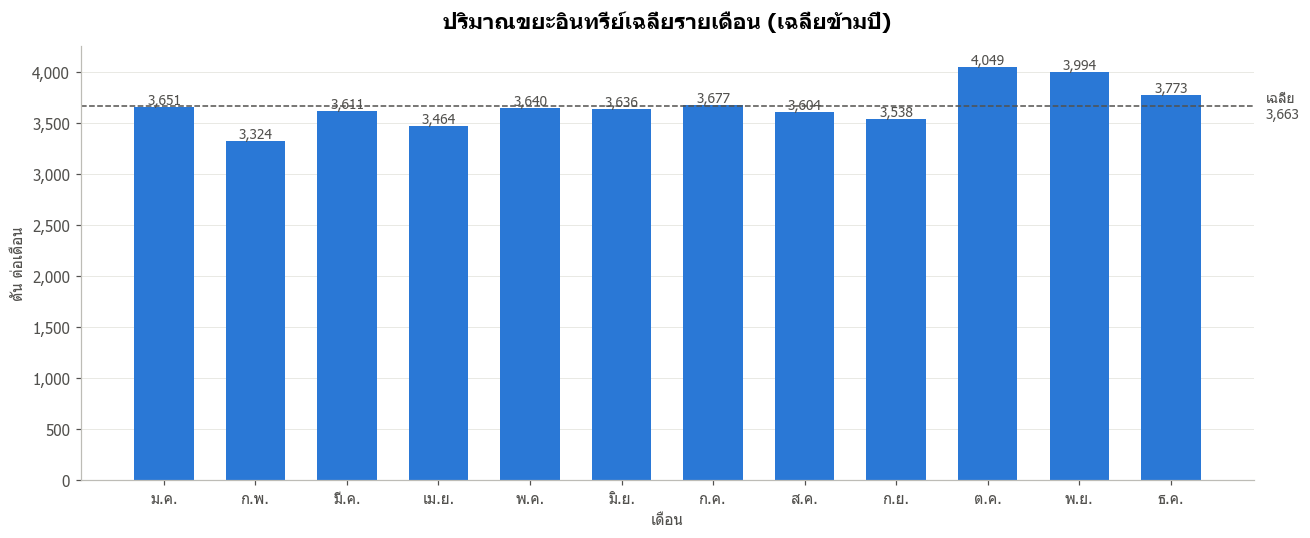

In [13]:
col = 'ขยะอินทรีย์ลงถัง(ตัน)'
ym = viz.groupby(['ปี', 'เดือน'])[col].sum().unstack('เดือน').reindex(columns=MONTHS)
avg = ym.mean()

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(MONTHS_SHORT, avg.values, color=PALETTE[0], width=0.65)
bar_labels(ax, bars)
ref_line(ax, avg.mean(), f'เฉลี่ย\n{avg.mean():,.0f}')
ax.yaxis.set_major_formatter(fmt_k); ax.grid(axis='x', visible=False)
ax.set_title('ปริมาณขยะอินทรีย์เฉลี่ยรายเดือน (เฉลี่ยข้ามปี)')
ax.set_xlabel('เดือน'); ax.set_ylabel('ตัน ต่อเดือน')
plt.tight_layout(); plt.show()

### 2.5 Heatmap: year × month
**What it does:** shows the total for every month of every year as a colored table (darker = more)

**How to read it:** read across a row to see the seasonality within a year, read down a column to compare the same month across years. Cells that are unusually light/dark may be months with missing data or special events

### 2.5 Heatmap: ปี × เดือน
**ทำอะไร:** แสดงยอดรวมของทุกเดือนในทุกปีเป็นตารางสี (สีเข้ม = ปริมาณมาก)

**วิธีอ่าน:** อ่านตามแถวเพื่อดูฤดูกาลภายในปี อ่านตามคอลัมน์เพื่อเทียบเดือนเดียวกันข้ามปี ช่องที่สีอ่อน/เข้มผิดปกติอาจเป็นเดือนที่ข้อมูลขาดหรือมีเหตุการณ์พิเศษ

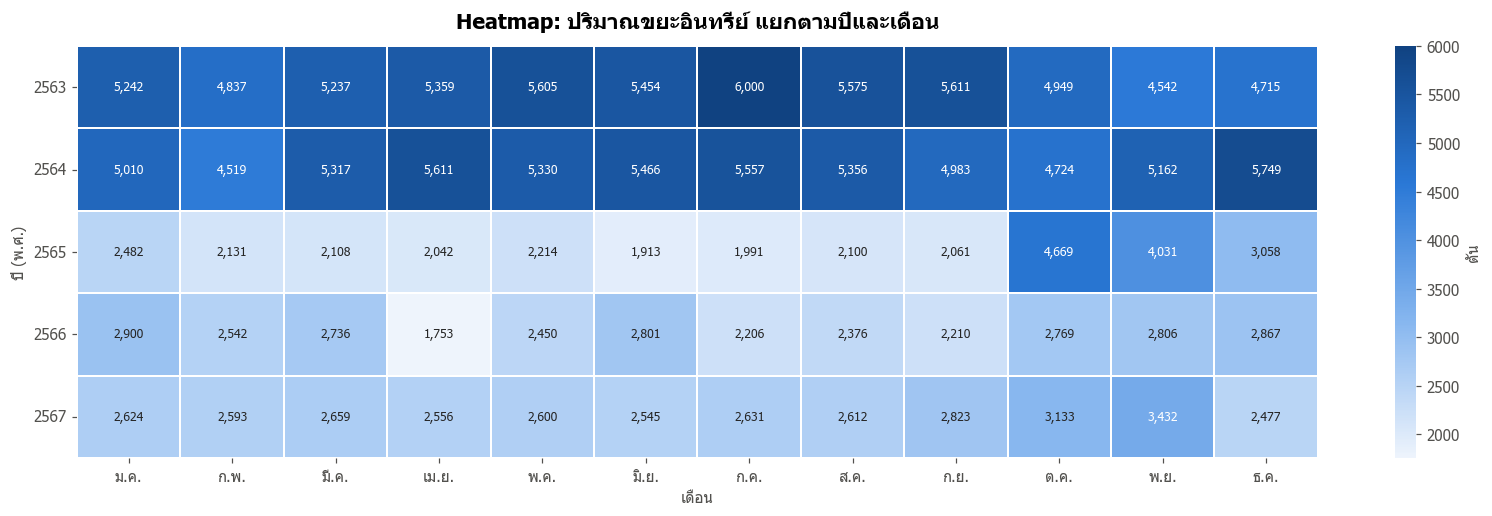

In [14]:
col = 'ขยะอินทรีย์ลงถัง(ตัน)'
ym = viz.groupby(['ปี', 'เดือน'])[col].sum().unstack('เดือน').reindex(columns=MONTHS)

fig, ax = plt.subplots(figsize=(15, 4.8))
sns.heatmap(ym.set_axis(MONTHS_SHORT, axis=1), annot=True, fmt=',.0f', cmap=SEQ_CMAP,
            linewidths=1, linecolor='white', annot_kws={'fontsize': 8},
            cbar_kws={'label': 'ตัน'}, ax=ax)
ax.set_title('Heatmap: ปริมาณขยะอินทรีย์ แยกตามปีและเดือน')
ax.set_xlabel('เดือน'); ax.set_ylabel('ปี (พ.ศ.)')
ax.tick_params(axis='y', rotation=0)
plt.tight_layout(); plt.show()

### 2.6 Horizontal bar chart: top 10 local governments by organic waste (all years combined)
**What it does:** sums the values per local government and picks the top 10 (`nlargest(10)`)

**How to read it:** shows which local governments most of the amount is concentrated in — useful for prioritizing areas (the number in brackets is the % of the province total)

### 2.6 กราฟแท่งแนวนอน: 10 อปท. ที่มีปริมาณขยะอินทรีย์สูงสุด (รวมทุกปี)
**ทำอะไร:** รวมค่าราย อปท. แล้วเลือก 10 อันดับแรก (`nlargest(10)`)

**วิธีอ่าน:** บอกว่าปริมาณส่วนใหญ่กระจุกตัวอยู่ที่ อปท. ใด — ใช้จัดลำดับความสำคัญของพื้นที่ (ตัวเลขในวงเล็บคือ % ของยอดรวมทั้งจังหวัด)

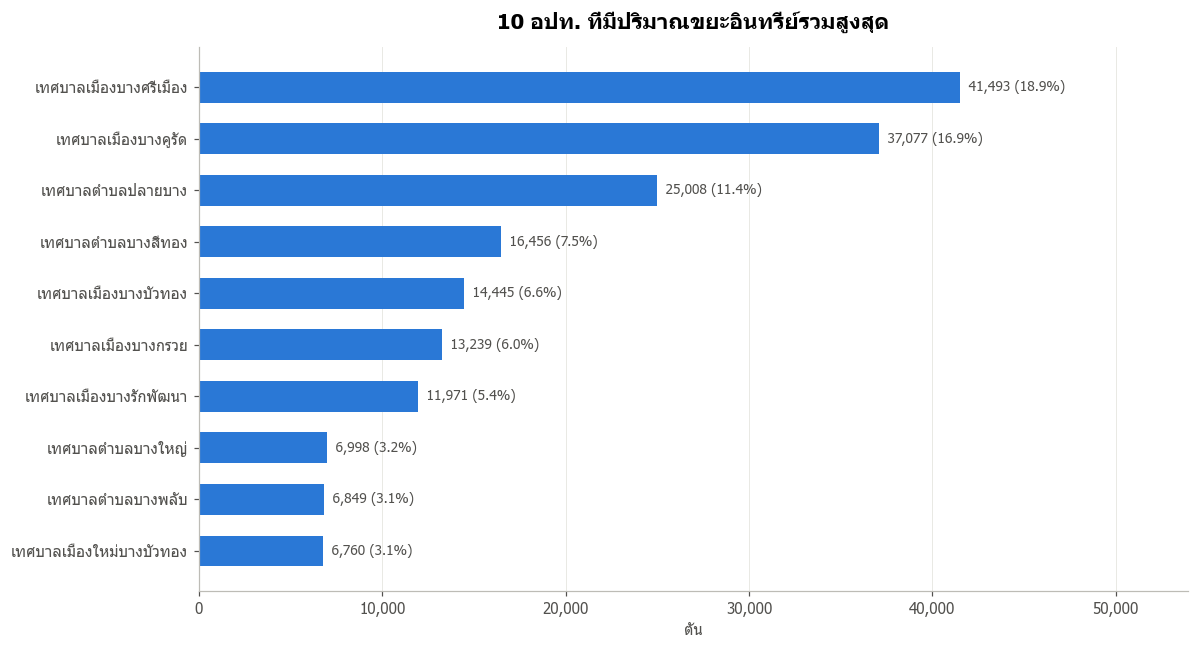

10 อันดับแรกคิดเป็น 82.0% ของยอดรวมทั้งจังหวัด (จาก 47 อปท.)


In [15]:
col = 'ขยะอินทรีย์ลงถัง(ตัน)'
by_apt = viz.groupby('อปท')[col].sum()
top = by_apt.nlargest(10).sort_values()

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(top.index, top.values, color=PALETTE[0], height=0.6)
for b, v in zip(bars, top.values):
    ax.text(v, b.get_y() + b.get_height() / 2, f'  {v:,.0f} ({v / by_apt.sum() * 100:.1f}%)',
            va='center', fontsize=9, color=TEXT)
ax.set_xlim(0, top.max() * 1.3)
ax.xaxis.set_major_formatter(fmt_k); ax.grid(axis='y', visible=False)
ax.set_title('10 อปท. ที่มีปริมาณขยะอินทรีย์รวมสูงสุด'); ax.set_xlabel('ตัน')
plt.tight_layout(); plt.show()
print(f'10 อันดับแรกคิดเป็น {top.sum() / by_apt.sum() * 100:.1f}% ของยอดรวมทั้งจังหวัด (จาก {by_apt.size} อปท.)')

### Paired bar chart: effect of fixing outliers (before vs after cleaning)
**What it does:** compares the yearly totals of the data **before** fixing outliers (the saved copy `df_before_clean`) with the data **after** fixing them

**How to read it:** if the two bars differ a lot, that year had outliers (e.g. numbers typed with the wrong number of digits) that were replaced with the median — this shows how much cleaning changes the analysis

### กราฟแท่งคู่: ผลของการแก้ค่าผิดปกติ (ก่อน vs หลังทำความสะอาด)
**ทำอะไร:** เทียบยอดรวมรายปีระหว่างข้อมูล **ก่อน** แก้ค่าโดด (`df_before_clean` ที่สำรองไว้) กับ **หลัง** แก้

**วิธีอ่าน:** ถ้าแท่งสองสีต่างกันมาก แปลว่าปีนั้นมีค่าผิดปกติ (เช่น พิมพ์ตัวเลขผิดหลัก) ที่ถูกแทนด้วยค่ามัธยฐาน — ทำให้เห็นว่าการทำความสะอาดมีผลต่อผลวิเคราะห์มากแค่ไหน

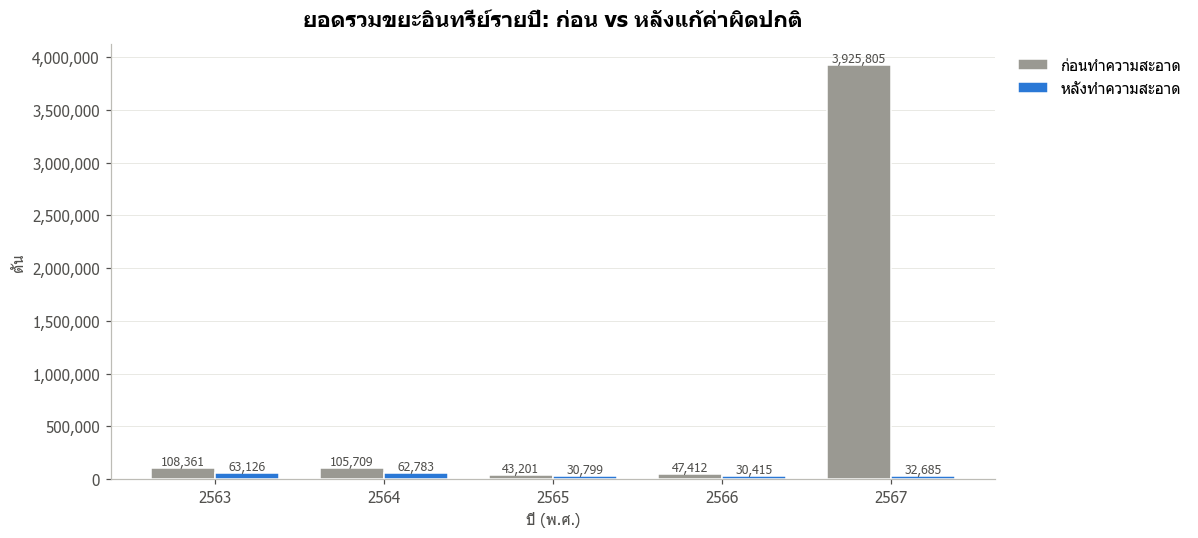

จำนวนแถวที่ถูกแก้ค่า: 38 แถว


,ก่อนทำความสะอาด,หลังทำความสะอาด,ส่วนต่าง
ปี,,,
2563,108361.2,63126.5,45234.7
2564,105709.3,62782.8,42926.5
2565,43201.4,30799.4,12402.1
2566,47411.8,30415.4,16996.4
2567,3925805.1,32684.7,3893120.4


In [16]:
col = 'ขยะอินทรีย์ลงถัง(ตัน)'
compare = pd.DataFrame({
    'ก่อนทำความสะอาด': df_before_clean.groupby('ปี')[col].sum(),
    'หลังทำความสะอาด': viz.groupby('ปี')[col].sum(),
})
x = np.arange(len(compare)); w = 0.38

fig, ax = plt.subplots(figsize=(11, 5))
b1 = ax.bar(x - w / 2, compare.iloc[:, 0], width=w, color=GRAY, label=compare.columns[0], edgecolor='white', linewidth=1)
b2 = ax.bar(x + w / 2, compare.iloc[:, 1], width=w, color=PALETTE[0], label=compare.columns[1], edgecolor='white', linewidth=1)
bar_labels(ax, b1, fontsize=8); bar_labels(ax, b2, fontsize=8)
ax.set_xticks(x, compare.index)
ax.yaxis.set_major_formatter(fmt_k); ax.grid(axis='x', visible=False)
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
ax.set_title('ยอดรวมขยะอินทรีย์รายปี: ก่อน vs หลังแก้ค่าผิดปกติ')
ax.set_xlabel('ปี (พ.ศ.)'); ax.set_ylabel('ตัน')
plt.tight_layout(); plt.show()

n_fixed = (df_before_clean[col] != df[col]).sum()
print(f'จำนวนแถวที่ถูกแก้ค่า: {n_fixed} แถว')
compare.assign(ส่วนต่าง=compare.iloc[:, 0] - compare.iloc[:, 1]).round(1)

### organic-waste separation rate relative to all municipal solid waste (% by district × year)
**What it does:** uses the municipal solid waste data (`clean_community.csv`) as the denominator and calculates

`rate (%) = amount of organic-waste separation ÷ total municipal solid waste × 100`

split by district and year, shown as a heatmap (darker = higher share)

**How to read it:** this number answers "what % of all the waste generated was separated/handled as organic-waste separation" — a fairer measure of sorting performance than raw amounts, because large districts naturally produce more waste

### อัตราคัดแยกขยะอินทรีย์ต่อขยะมูลฝอยชุมชนทั้งหมด (% รายอำเภอ × ปี)
**ทำอะไร:** นำข้อมูลขยะมูลฝอยชุมชน (`clean_community.csv`) มาเป็นตัวหาร แล้วคำนวณ

`อัตรา (%) = ปริมาณคัดแยกขยะอินทรีย์ ÷ ขยะมูลฝอยชุมชนทั้งหมด × 100`

แยกตามอำเภอและปี แสดงเป็น heatmap (สีเข้ม = สัดส่วนสูง)

**วิธีอ่าน:** ตัวเลขนี้ตอบคำถามว่า "ขยะที่เกิดขึ้นทั้งหมด ถูกแยก/จัดการเป็นคัดแยกขยะอินทรีย์ได้กี่ %" — เป็นตัวชี้วัดประสิทธิภาพการคัดแยกที่ยุติธรรมกว่าการดูปริมาณตรง ๆ เพราะอำเภอใหญ่ย่อมมีขยะมากอยู่แล้ว

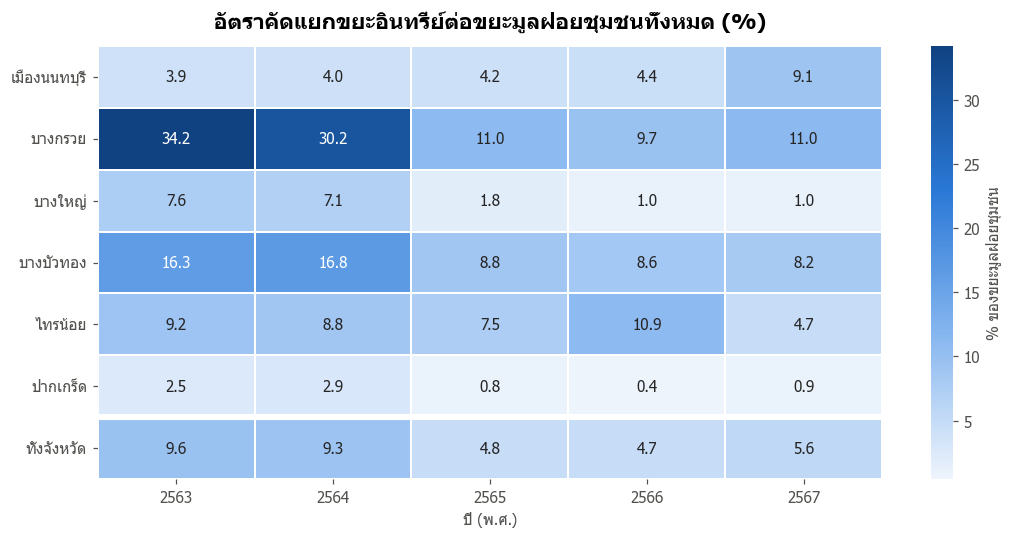

ปี,2563,2564,2565,2566,2567
อำเภอ,,,,,
เมืองนนทบุรี,3.94,4.03,4.17,4.42,9.06
บางกรวย,34.21,30.21,10.96,9.66,11.03
บางใหญ่,7.58,7.11,1.79,1.02,0.98
บางบัวทอง,16.33,16.80,8.84,8.58,8.19
ไทรน้อย,9.21,8.76,7.50,10.93,4.67
ปากเกร็ด,2.51,2.94,0.83,0.43,0.87
ทั้งจังหวัด,9.61,9.35,4.77,4.71,5.64


In [17]:
col = 'ขยะอินทรีย์ลงถัง(ตัน)'
comm = pd.read_csv('../data/clean/clean_community.csv')
comm_dy = comm.groupby(['อำเภอ', 'ปี'])['ขยะมูลฝอยชุมชน(ตัน)'].sum()
part_dy = viz.groupby(['อำเภอ', 'ปี'])[col].sum()
rate = (part_dy / comm_dy * 100).unstack('ปี').reindex([d for d in DIST_ORDER if d in set(viz['อำเภอ'])])

overall = viz.groupby('ปี')[col].sum() / comm.groupby('ปี')['ขยะมูลฝอยชุมชน(ตัน)'].sum() * 100
rate.loc['ทั้งจังหวัด'] = overall

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(rate, annot=True, fmt='.1f', cmap=SEQ_CMAP, linewidths=1, linecolor='white',
            cbar_kws={'label': '% ของขยะมูลฝอยชุมชน'}, ax=ax)
ax.axhline(len(rate) - 1, color='white', linewidth=4)
ax.set_title('อัตราคัดแยกขยะอินทรีย์ต่อขยะมูลฝอยชุมชนทั้งหมด (%)')
ax.set_xlabel('ปี (พ.ศ.)'); ax.set_ylabel('')
ax.tick_params(axis='y', rotation=0)
plt.tight_layout(); plt.show()
rate.round(2)

### Comparison: organic vs recyclable waste separated, by district (5 years combined)
**What it does:** reads `clean_recycle.csv` and compares the two side by side in the same unit (tonnes)

**How to read it:** shows which kind of sorting each district focuses on — districts with a low green (organic) bar but a large population are opportunities for wet-waste bin/composting programs

### เปรียบเทียบ: ขยะอินทรีย์ vs ขยะรีไซเคิล ที่คัดแยกได้ รายอำเภอ (รวม 5 ปี)
**ทำอะไร:** อ่าน `clean_recycle.csv` มาเทียบคู่กันในหน่วยตันเดียวกัน

**วิธีอ่าน:** ดูว่าแต่ละอำเภอเน้นการคัดแยกแบบไหน — อำเภอที่แท่งเขียว (อินทรีย์) ต่ำแต่มีประชากรมาก คือโอกาสในการทำโครงการถังขยะเปียก/ปุ๋ยหมัก

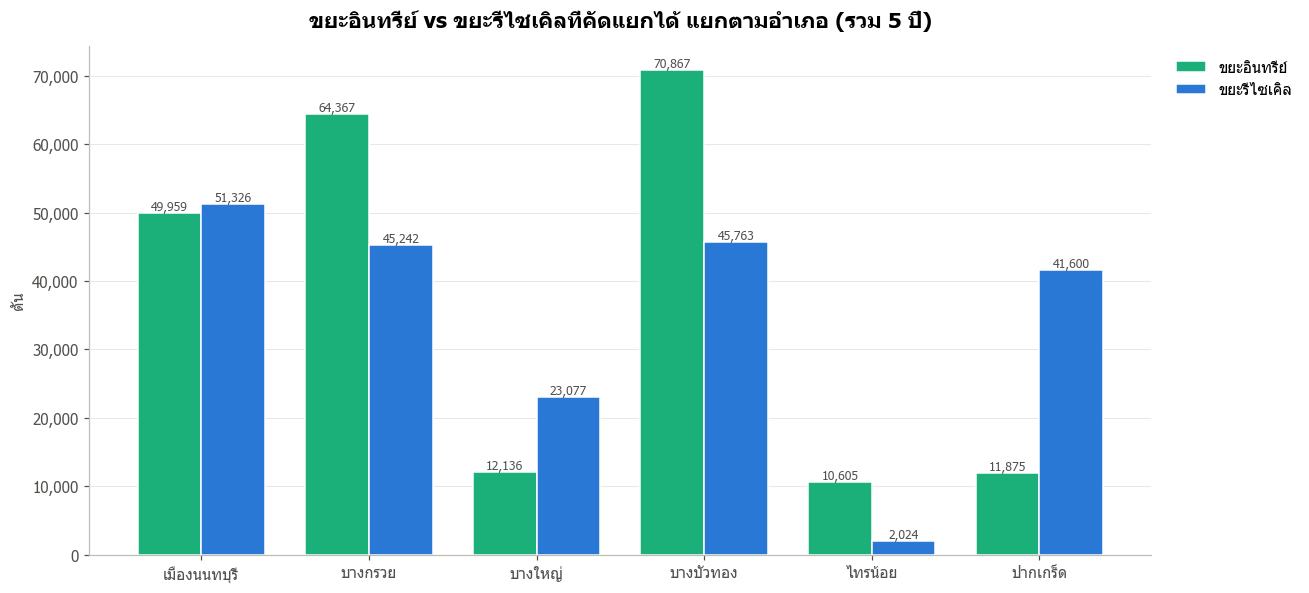

,ขยะอินทรีย์,ขยะรีไซเคิล
อำเภอ,,
เมืองนนทบุรี,49959.0,51326.2
บางกรวย,64366.9,45241.6
บางใหญ่,12136.0,23076.6
บางบัวทอง,70867.2,45763.3
ไทรน้อย,10605.0,2023.5
ปากเกร็ด,11874.7,41600.0


In [18]:
rec = pd.read_csv('../data/clean/clean_recycle.csv')
both = pd.DataFrame({
    'ขยะอินทรีย์': viz.groupby('อำเภอ')['ขยะอินทรีย์ลงถัง(ตัน)'].sum(),
    'ขยะรีไซเคิล': rec.groupby('อำเภอ')['ขยะรีไซเคิลลงถัง(ตัน)'].sum(),
}).reindex([d for d in DIST_ORDER if d in set(viz['อำเภอ'])])
x = np.arange(len(both)); w = 0.38
fig, ax = plt.subplots(figsize=(12, 5.5))
b1 = ax.bar(x - w / 2, both['ขยะอินทรีย์'], width=w, color=PALETTE[2], label='ขยะอินทรีย์', edgecolor='white', linewidth=1)
b2 = ax.bar(x + w / 2, both['ขยะรีไซเคิล'], width=w, color=PALETTE[0], label='ขยะรีไซเคิล', edgecolor='white', linewidth=1)
bar_labels(ax, b1, fontsize=8); bar_labels(ax, b2, fontsize=8)
ax.set_xticks(x, both.index)
ax.yaxis.set_major_formatter(fmt_k); ax.grid(axis='x', visible=False)
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
ax.set_title('ขยะอินทรีย์ vs ขยะรีไซเคิลที่คัดแยกได้ แยกตามอำเภอ (รวม 5 ปี)')
ax.set_ylabel('ตัน')
plt.tight_layout(); plt.show()
both.round(1)

---
## Key Findings

1. **Separated organic waste halved in 2565 (2022)** (~62,800 → ~30,800 tonnes) and has stayed at ~30,000–33,000 tonnes/year since
2. **The province's organic-waste separation rate is ~4.7–9.6%** of all waste, very low compared with the share of food scraps actually in the bins (~40%, from the waste-types notebook) — there is a lot of untapped potential
3. **Bang Bua Thong (32%) and Bang Kruai (29%) are the main sources of separated organic waste** — the top local governments are Bang Si Mueang Town Municipality (Mueang Nonthaburi), Bang Khu Rat Town Municipality (Bang Bua Thong) and Plai Bang Subdistrict Municipality (Bang Kruai). Pak Kret, which has the province's second-largest amount of waste, accounts for only ~5% of the province's separated organic waste
4. **Pak Kret and Bang Yai separate more recyclables than organic waste**, while Bang Bua Thong, Bang Kruai and Sai Noi are the opposite — each district focuses on different kinds of sorting

## สรุปข้อค้นพบ

1. **ขยะอินทรีย์ที่คัดแยกได้ลดลงครึ่งหนึ่งในปี 2565** (~62,800 → ~30,800 ตัน) และทรงตัวที่ ~30,000–33,000 ตัน/ปีหลังจากนั้น
2. **อัตราคัดแยกขยะอินทรีย์ทั้งจังหวัดอยู่ที่ ~4.7–9.6%** ของขยะทั้งหมด ซึ่งต่ำมากเมื่อเทียบกับสัดส่วนเศษอาหารในถังขยะจริง (~40% จาก notebook ประเภทขยะ) — ยังมีศักยภาพเหลืออีกมาก
3. **บางบัวทอง (32%) และบางกรวย (29%) เป็นแหล่งคัดแยกหลัก** — อปท. อันดับต้นคือเทศบาลเมืองบางศรีเมือง (เมืองนนทบุรี), เทศบาลเมืองบางคูรัด (บางบัวทอง) และเทศบาลตำบลปลายบาง (บางกรวย) ขณะที่ปากเกร็ดซึ่งมีขยะมากเป็นอันดับ 2 ของจังหวัด มีส่วนแบ่งเพียง ~5% ของขยะอินทรีย์ที่คัดแยกได้ทั้งจังหวัด
4. **ปากเกร็ดและบางใหญ่คัดแยกรีไซเคิลได้มากกว่าอินทรีย์** ส่วนบางบัวทอง บางกรวย และไทรน้อยกลับกัน — แต่ละอำเภอเน้นการคัดแยกต่างกัน